# 수원시 버스 정류장별 일일 승차 수요 예측 및 시각화 서비스

## 1. 목적·출처·범위
정류소ID와 날짜로 하루 `승차합계`를 예측하는 회귀 MVP이다. 데이터는 제공된 경기데이터드림 ‘경기도 정류소 별 승하차 인원 집계’의 수원시 2026년 6~8월 CSV이며, 다운로드 원문·수집 과정은 이 작업에서 재검증하지 않았다.

6~7월에 55일 이상 관측된 정류소 중 승차합계 상위 100개만 예측한다. 원본 CSV는 읽기 전용으로 사용한다. 초승·환승·하차·당일 승차합계는 입력에 사용하지 않는다. 시간대별 승차나 차량 혼잡도는 예측하지 않는다.

강의의 회귀 지표·EDA, 파이프라인의 누수 방지, 보고서 예시의 수행내용→결과→한계 순서를 참고한다. 참고 검토 범위는 `docs/reference_review.md`에 기록한다. 예시 성능 수치는 복사하지 않는다.

아래 셀을 위에서부터 실행한다. 공통 함수는 `train.py`에 한글 docstring·처리 이유 주석과 함께 정의되어 앱에서도 같은 피처 함수를 쓴다.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from train import (ROOT, RAW_FEATURES, load_data, select_stations, make_features,
                   split_data, compare_models, fit_final_and_save, save_figures)
pd.set_option('display.max_columns', 12)
df, quality = load_data()
display(pd.Series(quality, name='품질 검증'))
display(df.head())
display(df.dtypes.to_frame('자료형'))
if not quality['matches_expected']:
    print('주의: 지시문의 예상 129,049행·1,435개·92일과 다릅니다.')

rows                                                                  129049
columns                    [승하차일자, 관할관청, 정류소ID, 정류소번호, 정류소명, 승차합계, 초승, 환승...
station_count                                                           1435
date_count                                                                92
date_start                                                        2026-06-01
date_end                                                          2026-08-31
missing_by_column          {'승하차일자': 0, '관할관청': 0, '정류소ID': 0, '정류소번호': 0...
duplicate_station_dates                                                    0
zero_boarding_rows                                                      5481
absent_station_dates                                                    2971
sha256                     67eab89c329abbfe75421c9b25e2aec0dadd9dfc699b20...
matches_expected                                                        True
Name: 품질 검증, dtype: object

,승하차일자,관할관청,정류소ID,정류소번호,정류소명,승차합계,초승,환승,하차
0,2026-06-01,수원시,200000001,01165,하광교느티나무,0,0,0,15
1,2026-06-01,수원시,200000002,01173,하광교,0,0,0,41
2,2026-06-01,수원시,200000003,01180,비석거리입구,3,3,0,33
3,2026-06-01,수원시,200000004,01196,문암골,5,5,0,44
4,2026-06-01,수원시,200000005,01205,광교산입구.경기대수원캠퍼스,19,16,3,243


,자료형
승하차일자,datetime64[ns]
관할관청,object
정류소ID,string[python]
정류소번호,string[python]
정류소명,object
승차합계,int64
초승,int64
환승,int64
하차,int64


## 2. 데이터 구조·기초 품질·전처리
원본 9개 컬럼과 기간·관할관청·결측·중복·음수·비유한 인원을 검사한다. ID·정류소번호는 문자열로 읽어 선행 0과 식별자 의미를 보존한다. 실제 0명 관측은 유지하고, 없는 정류소·날짜 조합은 0명으로 만들지 않는다. 이상치라고 큰 수요를 임의 제거하지 않는다. 예상 규모와 실제 결과의 일치 여부도 출력한다.

In [2]:
display(df['승차합계'].describe().to_frame('일일 승차 인원'))
display(df.groupby(df['승하차일자'].dt.month).agg(관측행=('승차합계','size'), 승차합계=('승차합계','sum'), 관측일평균=('승차합계','mean')))
stations = select_stations(df)
selected, parts = split_data(df, stations)
display(stations.head(10))
display(pd.DataFrame({name: {'행 수':len(p), '시작':str(p['승하차일자'].min().date()), '종료':str(p['승하차일자'].max().date())} for name,p in parts.items()}).T)
print('선정 정류소 수:',len(stations), '| 최소 관측일:',stations['observed_days'].min())

,일일 승차 인원
count,129049.000000
mean,267.656355
std,555.957640
min,0.000000
25%,19.000000
50%,88.000000
75%,283.000000
max,8348.000000


,관측행,승차합계,관측일평균
승하차일자,,,
6,42479,11747825,276.556063
7,43416,11571930,266.536070
8,43154,11221030,260.022941


,정류소ID,observed_days,total_boardings,정류소번호,정류소명
0,202000219,61,434484,03017,수원역7번출구.AK플라자
1,202000224,61,424194,03164,매산시장
2,202000106,61,387179,03195,수원역7번출구.AK플라자
3,202000105,61,356923,03196,수원역6번출구.AK플라자
4,202000208,61,324138,03015,수원역4번출구.노보텔수원
5,203000150,61,222655,04072,그대가프리미어아파트.망포역3번출구
6,202000030,61,209249,03056,팔달문
7,203000399,61,176390,04396,광교중앙.경기도청.아주대역환승센터
8,203000345,61,165148,04325,망포역4번출구.영통2동행정복지센터
9,202000253,61,157671,03134,수원전통문화관.장안동


,행 수,시작,종료
Train,3000,2026-06-01,2026-06-30
Validation,3100,2026-07-01,2026-07-31
Test,3100,2026-08-01,2026-08-31


선정 정류소 수: 100 | 최소 관측일: 61


## 3. EDA: 월별·요일별 수요 분포
상위 정류소에 한정한 6~8월 관측 분포를 기술한다. 전체 수원시 분포로 일반화하지 않는다. 8월의 기술 통계는 모델 입력·튜닝·선정에 사용하지 않는다. 월별 총합은 날짜 수가 다르므로 관측일 평균과 함께 확인한다. 박스플롯의 극단점은 가독성을 위해 숨기되 원래 학습·평가 행은 유지한다.

In [3]:
eda = selected.assign(month=selected['승하차일자'].dt.month, weekday=selected['승하차일자'].dt.dayofweek)
display(eda.groupby('month')['승차합계'].agg(['count','mean','median','sum']))
display(eda.groupby('weekday')['승차합계'].agg(['count','mean','median']))
display(make_features(parts['Train'][RAW_FEATURES].head()))

,count,mean,median,sum
month,,,,
6,3000,1813.588000,1457.0,5440764
7,3100,1715.124839,1350.0,5316887
8,3100,1671.378710,1321.0,5181274


,count,mean,median
weekday,,,
0,1400,1795.801429,1442.5
1,1300,1882.733077,1512.0
2,1300,1841.465385,1482.5
3,1300,1880.516154,1507.5
4,1300,1930.347692,1545.5
5,1300,1563.724615,1229.0
6,1300,1227.984615,964.0


,station,weekday,weekend,month,day
64,200000069,0,0,6,1
75,200000080,0,0,6,1
81,200000088,0,0,6,1
86,200000093,0,0,6,1
89,200000096,0,0,6,1


## 4. 피처·시간 검증·모델 비교
학습 6월 → 검증 7월 → 최종 테스트 8월로 나눈다. 범주형은 정류소ID와 요일, 수치형은 주말 여부·월·일이다. ID에 크기 의미를 부여하지 않으며 `OneHotEncoder(handle_unknown='ignore')`를 적용한다. 날짜 파생·인코딩·스케일링·모델을 Pipeline으로 연결하고 학습 구간에만 fit한다.

Dummy(mean), Ridge(alpha=1), RandomForest(60 trees, max_depth=20, min_samples_leaf=3)를 비교한다. MVP의 시간·용량 제약에 따라 RF 크기를 고정하고 탐색하지 않는다. 7월 MAE가 최소인 후보를 선정한다. 학습/검증 지표는 모두 6월 fit 모델에서 계산한다. 음수 예측은 평가·앱에서 일관되게 0으로 제한한다.

**검증 해석상의 제한:** 대상 정류소는 지시에 따라 6~7월로 사전 선정하므로 7월 데이터가 대상 집합 결정에는 쓰인다. 7월 성능은 그 집합에 조건부인 결과이며 완전히 독립적인 대상 선정 검증은 아니다. 8월은 선정에도 전혀 사용하지 않는다.

In [4]:
# 테스트를 보지 않고 검증 MAE만으로 후보를 확정한다.
candidate, comparison, winner = compare_models(parts)
display(comparison)
print('선택 모델:',winner)

,model,split,rows,MAE,RMSE,R2,fit_seconds
0,Dummy,Train,3000,814.095403,1279.194875,0.000000,0.030541
1,Dummy,Validation,3100,815.270508,1225.172040,-0.006501,0.044382
2,Ridge,Train,3000,193.888837,274.989122,0.953788,0.031450
3,Ridge,Validation,3100,215.933469,297.516533,0.940647,0.044942
4,RandomForest,Train,3000,302.480333,376.342733,0.913445,0.657101
5,RandomForest,Validation,3100,329.459518,398.001459,0.893784,0.694097


선택 모델: Ridge


## 5. 최종 재학습·단 한 번의 테스트 평가·저장
선정 후보를 복제하여 6~7월 전체 관측으로 다시 학습한다. 8월 예측을 한 번 생성하고 MAE·RMSE·R²를 계산한다. 이후 표·그림은 같은 저장 예측을 재사용한다. Final training 지표는 6~7월 재학습 모델의 적합도로, 후보 Train·Validation 지표와 구분한다. 저장한 joblib은 날짜와 정류소ID 입력부터 변환하며 공통 함수가 있는 train.py를 함께 유지해야 한다.

In [5]:
final_model, metrics, predictions = fit_final_and_save(
    df, quality, stations, selected, parts, candidate, comparison, winner)
display(pd.DataFrame([{'구간':'Final training (Jun-Jul)', **metrics['final_training']},
                      {'구간':'Final test (Aug)', **metrics['test']}]))
print('저장 모델 크기:',metrics['model_bytes'],'bytes')
display(predictions.head(15))

,구간,start,end,rows,MAE,RMSE,R2
0,Final training (Jun-Jul),2026-06-01,2026-07-31,6100.0,182.971792,269.904057,0.953454
1,Final test (Aug),NaN,NaN,NaN,218.860248,299.136116,0.938699


저장 모델 크기: 2909 bytes


,승하차일자,정류소ID,승차합계,prediction
85957,2026-08-01,200000069,602,693.372277
85968,2026-08-01,200000080,1532,1702.743245
85974,2026-08-01,200000088,2271,1606.630342
85979,2026-08-01,200000093,1652,1579.920665
85982,2026-08-01,200000096,990,826.872277
85990,2026-08-01,200000104,868,657.098084
85997,2026-08-01,200000111,987,900.581955
86025,2026-08-01,200000139,1517,1212.710987
86046,2026-08-01,200000160,782,729.259374
86047,2026-08-01,200000161,510,741.404536


mkdir -p failed for path C:\Users\human-04\AppData\Local\matplotlib: [WinError 5] 액세스가 거부되었습니다: 'C:\\Users\\human-04\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\human-04\AppData\Local\Temp\matplotlib-i6vldh6k because there was an issue with the default path (C:\Users\human-04\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


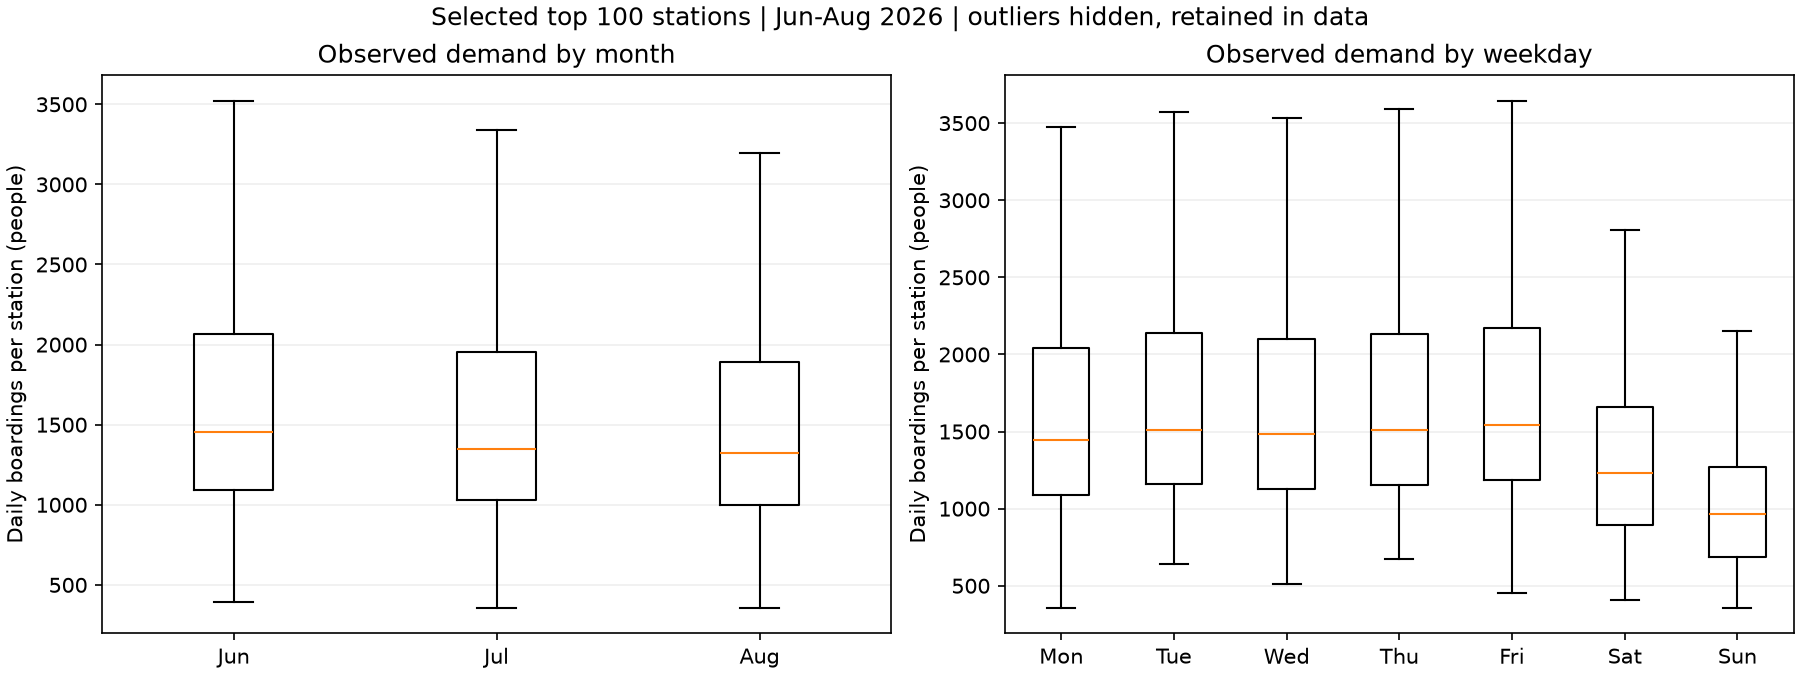

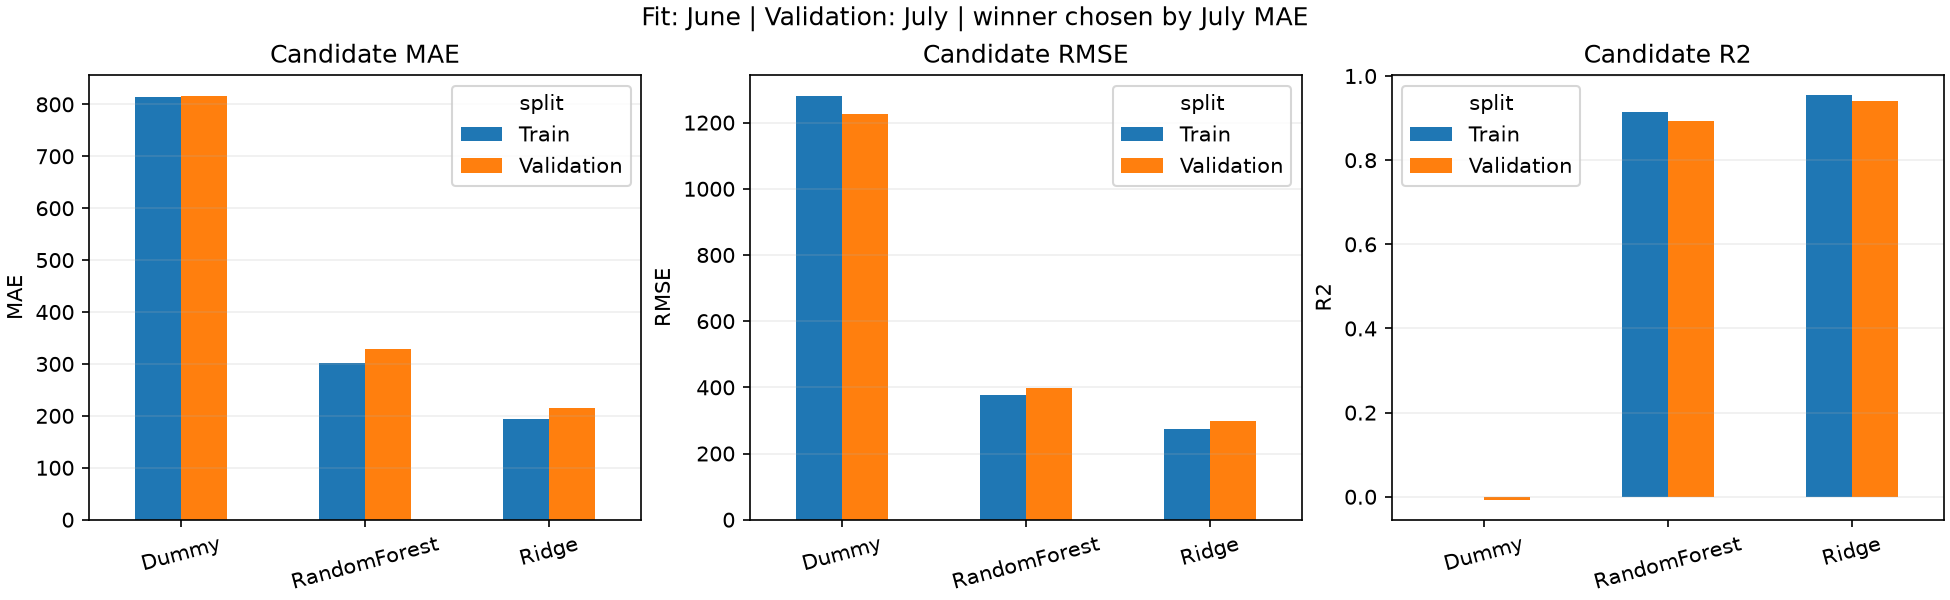

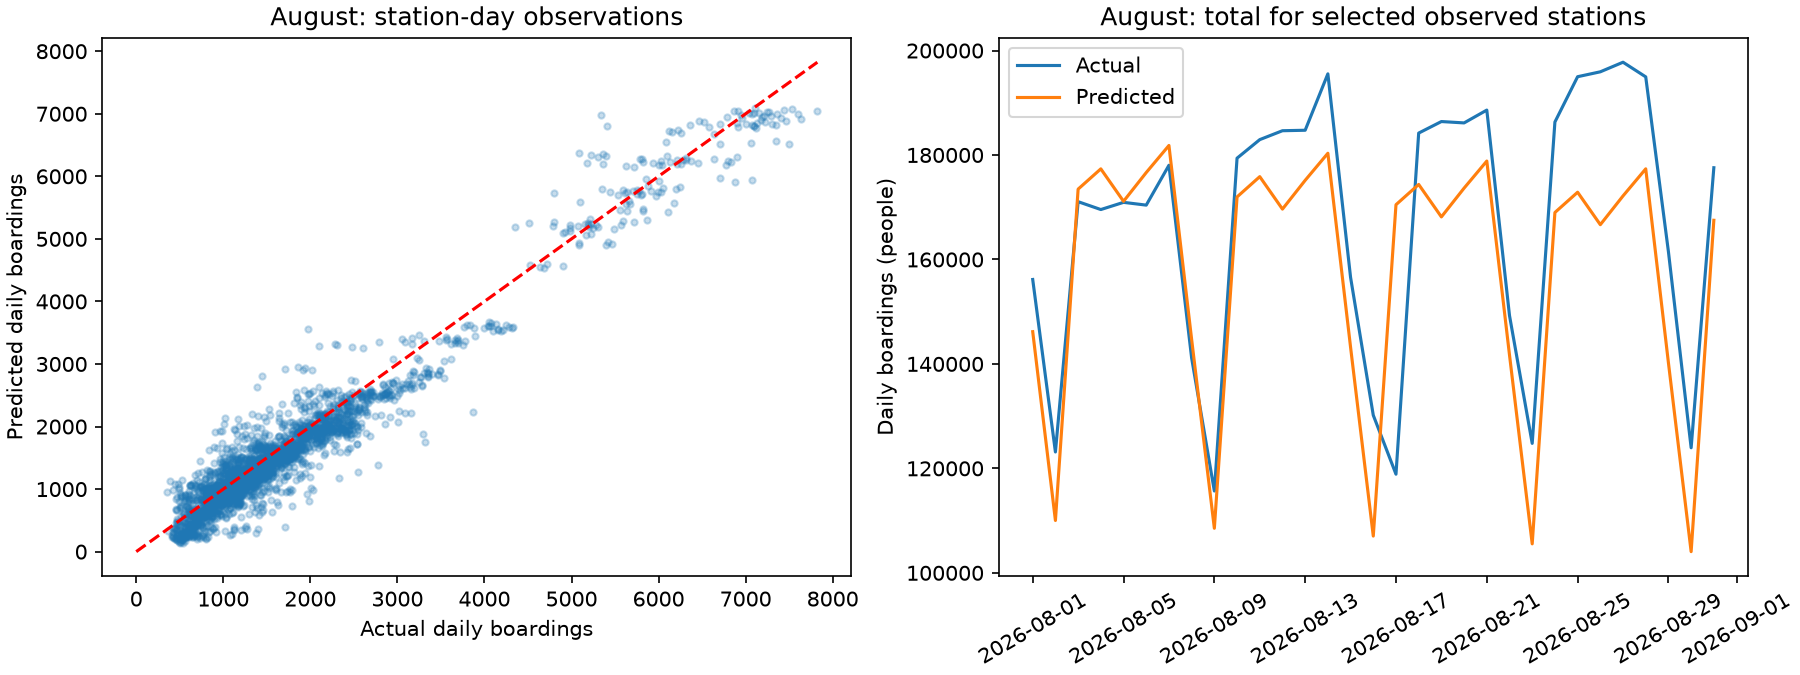

In [6]:
# 동일 테스트 예측을 재사용해 보고서 그림을 생성한다.
save_figures(selected, comparison, predictions)
for name in ['demand_patterns.png','model_comparison.png','test_actual_vs_predicted.png']:
    display(Image(filename=str(ROOT / 'outputs/figures' / name)))

## 6. 결과 해석·한계·서비스
MAE는 관측 정류소·하루당 절대 오차의 평균(명), RMSE는 큰 오차에 민감한 명 단위 지표, R²는 관측 분산 대비 설명력이다. 이는 ‘정확도 %’나 개별 날짜의 예측구간을 뜻하지 않는다. 실제 지표는 위 실행 결과 및 outputs/metrics.json을 따른다.

앱: `python -m streamlit run app.py`. 정류소명·번호·ID를 구분하여 선택하고 날짜별 예상 일일 인원과 관측 패턴·테스트 지표를 보여준다. 6~8월의 과거 3개월 자료 중 모델 학습은 6~7월이며 8월은 테스트다.

관측은 여름 3개월뿐이며 날씨·공휴일·방학·행사·노선 및 배차 변경을 반영하지 않는다. 8월 이후 및 다른 연도의 날짜는 계절 변화·장기 추세를 학습하지 못한 제한적 추정이다. 고수요 정류소 중심의 표본이므로 저수요·신규 정류소로 일반화하지 않는다. 없는 관측은 미관측으로 남아 있다. 향후 더 긴 기간 및 공휴일·날씨 데이터를 확보한 뒤 새로운 독립 기간에서 검증해야 한다. 이번 MVP에는 추가 기능·튜닝·배포를 포함하지 않는다.